In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

data_path = "/content/drive/MyDrive/APS360_Wafer_Project/data/LSWMD.pkl"

print(os.path.exists(data_path))

True


In [ ]:
import os

file_size = os.path.getsize(data_path)

print("File size:", file_size / (1024**3), "GB")

File size: 1.9515920216217637 GB


In [ ]:
import pandas as pd

df = pd.read_pickle(
    data_path,
    compression=None
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (811457, 6)


In [ ]:
# 1. Inspect column names
print("Column names:")
print(df.columns.tolist())

print("\n" + "=" * 50)

# 2. Inspect data types
print("Data types:")
print(df.dtypes)

print("\n" + "=" * 50)

# 3. Inspect missing values
print("Missing values:")
print(df.isnull().sum())

print("\n" + "=" * 50)

# 4. Inspect the first five rows (metadata only)
print("First five rows:")
print(df.drop(columns=["waferMap"]).head())

Column names:
['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType']

Data types:
waferMap           object
dieSize           float64
lotName            object
waferIndex        float64
trianTestLabel     object
failureType        object
dtype: object

Missing values:
waferMap          0
dieSize           0
lotName           0
waferIndex        0
trianTestLabel    0
failureType       0
dtype: int64

First five rows:
   dieSize lotName  waferIndex trianTestLabel failureType
0   1683.0    lot1         1.0   [[Training]]    [[none]]
1   1683.0    lot1         2.0   [[Training]]    [[none]]
2   1683.0    lot1         3.0   [[Training]]    [[none]]
3   1683.0    lot1         4.0   [[Training]]    [[none]]
4   1683.0    lot1         5.0   [[Training]]    [[none]]


In [ ]:
print("First 10 failureType values:")

for i in range(10):
    print(i, repr(df["failureType"].iloc[i]))

First 10 failureType values:
0 array([['none']], dtype='<U4')
1 array([['none']], dtype='<U4')
2 array([['none']], dtype='<U4')
3 array([['none']], dtype='<U4')
4 array([['none']], dtype='<U4')
5 array([['none']], dtype='<U4')
6 array([['none']], dtype='<U4')
7 array([['none']], dtype='<U4')
8 array([['none']], dtype='<U4')
9 array([['none']], dtype='<U4')


In [ ]:
print("First 10 wafer map dimensions:")

for i in range(10):
    wafer = df["waferMap"].iloc[i]
    print(i, wafer.shape)

First 10 wafer map dimensions:
0 (45, 48)
1 (45, 48)
2 (45, 48)
3 (45, 48)
4 (45, 48)
5 (45, 48)
6 (45, 48)
7 (45, 48)
8 (45, 48)
9 (45, 48)


In [ ]:
wafer_sizes = df["waferMap"].apply(lambda x: x.shape)

print("\nMost common wafer dimensions:")
print(wafer_sizes.value_counts().head(15))


Most common wafer dimensions:
waferMap
(32, 29)    108687
(25, 27)     64083
(49, 39)     39323
(26, 26)     30078
(30, 34)     29513
(33, 33)     23886
(33, 29)     20276
(39, 37)     15327
(52, 59)     14812
(31, 31)     14569
(39, 31)     13562
(29, 26)     13247
(27, 25)     12655
(64, 71)     11692
(31, 28)     10788
Name: count, dtype: int64


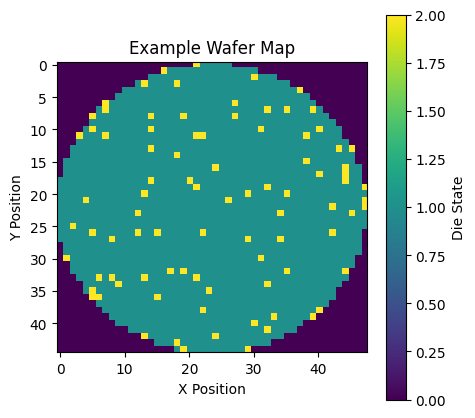

Wafer shape: (45, 48)
Unique pixel values: [0 1 2]


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

sample = df["waferMap"].iloc[0]

plt.figure(figsize=(5, 5))
plt.imshow(sample, cmap="viridis")
plt.colorbar(label="Die State")
plt.title("Example Wafer Map")
plt.xlabel("X Position")
plt.ylabel("Y Position")
plt.show()

print("Wafer shape:", sample.shape)
print("Unique pixel values:", np.unique(sample))

In [ ]:

import numpy as np
import pandas as pd

def extract_label(x):
    # Handle missing or empty values
    while isinstance(x, (np.ndarray, list)):
        if len(x) == 0:
            return "unknown"
        x = x[0]

    if pd.isna(x):
        return "unknown"

    return str(x).strip()

# Extract labels
df["failure_label"] = df["failureType"].apply(extract_label)
df["dataset_split"] = df["trianTestLabel"].apply(extract_label)

print("Failure type distribution:")
print(df["failure_label"].value_counts(dropna=False))

print("\nDataset split distribution:")
print(df["dataset_split"].value_counts(dropna=False))

print("\nNumber of unique failure types:")
print(df["failure_label"].nunique())


Failure type distribution:
failure_label
unknown      638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64

Dataset split distribution:
dataset_split
unknown     638507
Test        118595
Training     54355
Name: count, dtype: int64

Number of unique failure types:
10


In [ ]:

from collections import Counter

pixel_counts = Counter()

for wafer in df["waferMap"]:
    values, counts = np.unique(wafer, return_counts=True)
    for value, count in zip(values, counts):
        pixel_counts[int(value)] += int(count)

print("Pixel value distribution:")
for value, count in sorted(pixel_counts.items()):
    print(f"Value {value}: {count:,}")


Pixel value distribution:
Value 0: 422,404,108
Value 1: 1,393,453,681
Value 2: 100,437,508


In [ ]:

# Keep only samples with usable failure labels
df_labeled = df[df["failure_label"] != "unknown"].copy()

print("Total labeled samples:", len(df_labeled))
print("\nClass distribution:")
print(df_labeled["failure_label"].value_counts())

print("\nClass percentages:")
print(
    (df_labeled["failure_label"].value_counts(normalize=True) * 100)
    .round(2)
)


Total labeled samples: 172950

Class distribution:
failure_label
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64

Class percentages:
failure_label
none         85.24
Edge-Ring     5.60
Edge-Loc      3.00
Center        2.48
Loc           2.08
Scratch       0.69
Random        0.50
Donut         0.32
Near-full     0.09
Name: proportion, dtype: float64


In [ ]:

# Check wafer map dimensions
df_labeled["wafer_shape"] = df_labeled["waferMap"].apply(
    lambda x: x.shape
)

print("Most common wafer dimensions:")
print(df_labeled["wafer_shape"].value_counts().head(15))

# Check pixel values in labeled samples
pixel_values = set()

for wafer in df_labeled["waferMap"]:
    pixel_values.update(np.unique(wafer).tolist())

print("\nUnique pixel values:", sorted(pixel_values))

# Check for empty wafer maps
empty_maps = df_labeled["waferMap"].apply(
    lambda x: x.size == 0
).sum()

print("Empty wafer maps:", empty_maps)


Most common wafer dimensions:
wafer_shape
(25, 27)    18781
(26, 26)    14366
(30, 34)    12400
(29, 26)    11751
(27, 25)    10682
(39, 37)    10173
(33, 29)     8125
(42, 44)     6724
(44, 41)     6134
(41, 33)     5091
(35, 31)     4331
(25, 26)     4174
(41, 38)     4152
(33, 37)     3729
(29, 27)     2872
Name: count, dtype: int64

Unique pixel values: [0, 1, 2]
Empty wafer maps: 0


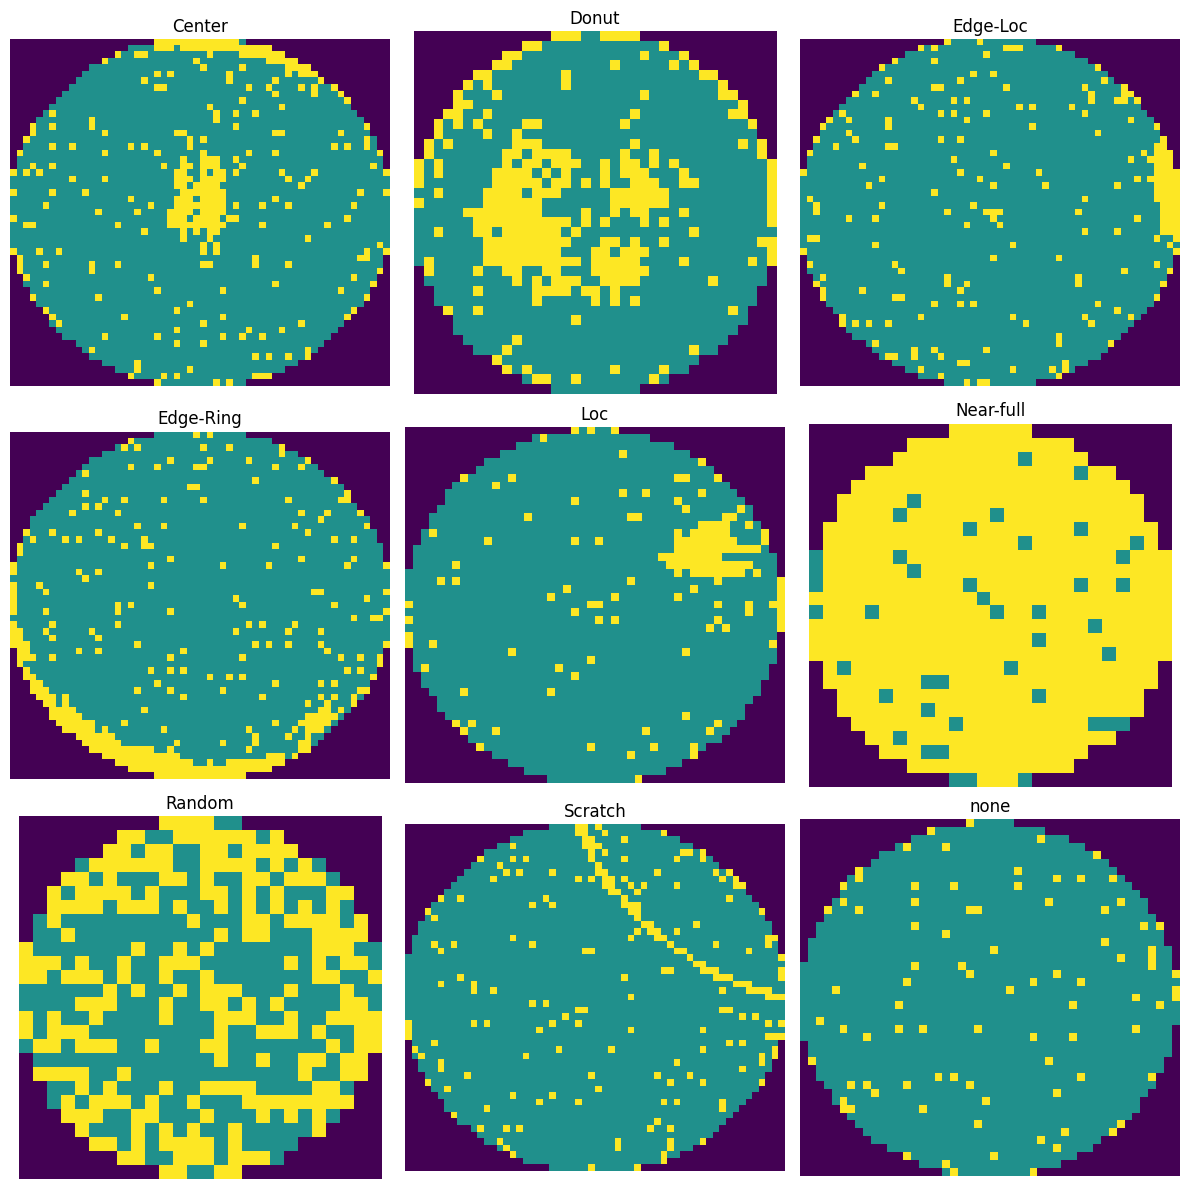

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

classes = sorted(df_labeled["failure_label"].unique())

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes = axes.flatten()

for i, label in enumerate(classes):
    sample = df_labeled[
        df_labeled["failure_label"] == label
    ]["waferMap"].iloc[0]

    axes[i].imshow(sample, cmap="viridis", interpolation="nearest")
    axes[i].set_title(label)
    axes[i].axis("off")

plt.tight_layout()
plt.show()


Original shape: (45, 48)
Resized shape: (64, 64)
Original pixel values: [0 1 2]
Resized pixel values: [0 1 2]


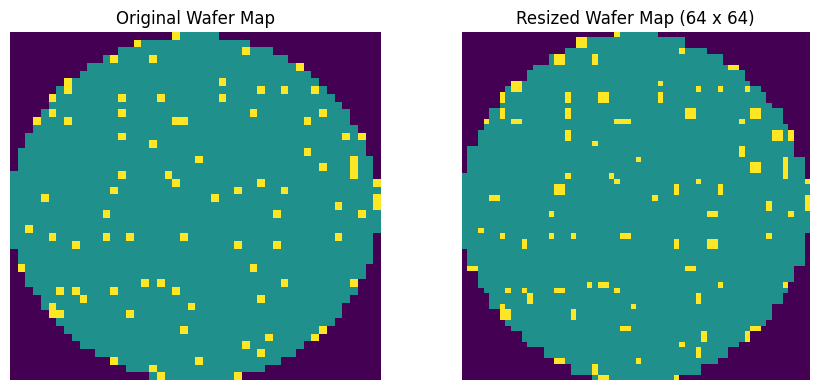

In [ ]:

from PIL import Image

# Select one wafer map
sample = df_labeled["waferMap"].iloc[0]

# Resize using nearest-neighbor interpolation
sample_resized = np.array(
    Image.fromarray(sample.astype(np.uint8)).resize(
        (64, 64),
        resample=Image.Resampling.NEAREST
    )
)

print("Original shape:", sample.shape)
print("Resized shape:", sample_resized.shape)
print("Original pixel values:", np.unique(sample))
print("Resized pixel values:", np.unique(sample_resized))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(sample, cmap="viridis", interpolation="nearest")
axes[0].set_title("Original Wafer Map")

axes[1].imshow(sample_resized, cmap="viridis", interpolation="nearest")
axes[1].set_title("Resized Wafer Map (64 x 64)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import train_test_split

# Keep the original row indices
all_indices = df_labeled.index.to_numpy()
all_labels = df_labeled["failure_label"].to_numpy()

# First split: 70% training, 30% remaining
train_idx, temp_idx = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=42,
    stratify=all_labels
)

# Second split: 15% validation, 15% test
temp_labels = df_labeled.loc[temp_idx, "failure_label"]

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Test samples:", len(test_idx))

print("\nTraining class distribution:")
print(df_labeled.loc[train_idx, "failure_label"].value_counts())

print("\nValidation class distribution:")
print(df_labeled.loc[val_idx, "failure_label"].value_counts())

print("\nTest class distribution:")
print(df_labeled.loc[test_idx, "failure_label"].value_counts())


Training samples: 121065
Validation samples: 25942
Test samples: 25943

Training class distribution:
failure_label
none         103202
Edge-Ring      6776
Edge-Loc       3632
Center         3006
Loc            2515
Scratch         835
Random          606
Donut           389
Near-full       104
Name: count, dtype: int64

Validation class distribution:
failure_label
none         22114
Edge-Ring     1452
Edge-Loc       778
Center         644
Loc            539
Scratch        179
Random         130
Donut           83
Near-full       23
Name: count, dtype: int64

Test class distribution:
failure_label
none         22115
Edge-Ring     1452
Edge-Loc       779
Center         644
Loc            539
Scratch        179
Random         130
Donut           83
Near-full       22
Name: count, dtype: int64


In [ ]:

import torch
from torch.utils.data import Dataset
from PIL import Image
import numpy as np

class WaferDataset(Dataset):
    def __init__(self, dataframe, indices, class_to_idx):
        self.data = dataframe.loc[indices]
        self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        wafer = row["waferMap"].astype(np.uint8)

        # Resize to 64 x 64
        image = Image.fromarray(wafer).resize(
            (64, 64),
            resample=Image.Resampling.NEAREST
        )

        # Normalize pixel values from [0, 2] to [0, 1]
        image = np.array(image, dtype=np.float32) / 2.0

        # Add channel dimension: (1, 64, 64)
        image = torch.from_numpy(image).unsqueeze(0)

        label = self.class_to_idx[row["failure_label"]]
        label = torch.tensor(label, dtype=torch.long)

        return image, label


# Define consistent class indices
classes = sorted(df_labeled["failure_label"].unique())
class_to_idx = {
    label: i for i, label in enumerate(classes)
}

print("Class mapping:", class_to_idx)

train_dataset = WaferDataset(df_labeled, train_idx, class_to_idx)
val_dataset = WaferDataset(df_labeled, val_idx, class_to_idx)
test_dataset = WaferDataset(df_labeled, test_idx, class_to_idx)

# Check one sample
image, label = train_dataset[0]

print("\nImage shape:", image.shape)
print("Image range:", image.min().item(), image.max().item())
print("Label index:", label.item())
print("Label name:", classes[label.item()])


Class mapping: {'Center': 0, 'Donut': 1, 'Edge-Loc': 2, 'Edge-Ring': 3, 'Loc': 4, 'Near-full': 5, 'Random': 6, 'Scratch': 7, 'none': 8}

Image shape: torch.Size([1, 64, 64])
Image range: 0.0 1.0
Label index: 8
Label name: none


In [ ]:

from torch.utils.data import DataLoader

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

print("CUDA available:", torch.cuda.is_available())


Batch image shape: torch.Size([64, 1, 64, 64])
Batch label shape: torch.Size([64])
CUDA available: True


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

class WaferANN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 64, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 9)
        )

    def forward(self, x):
        return self.network(x)

ann_model = WaferANN().to(device)

print(ann_model)


Using device: cuda
WaferANN(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.3, inplace=False)
    (7): Linear(in_features=128, out_features=9, bias=True)
  )
)


In [ ]:

import numpy as np

train_labels = df_labeled.loc[train_idx, "failure_label"]

class_counts = np.array([
    (train_labels == label).sum()
    for label in classes
])

# Balanced class weights
class_weights = len(train_labels) / (
    len(classes) * class_counts
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class weights:")
for label, weight in zip(classes, class_weights.cpu().numpy()):
    print(f"{label}: {weight:.4f}")


Class weights:
Center: 4.4749
Donut: 34.5801
Edge-Loc: 3.7037
Edge-Ring: 1.9852
Loc: 5.3486
Near-full: 129.3429
Random: 22.1975
Scratch: 16.1098
none: 0.1303


In [ ]:

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.Adam(
    ann_model.parameters(),
    lr=0.001
)

num_epochs = 10


In [ ]:

from sklearn.metrics import f1_score, accuracy_score
import copy

train_losses = []
val_losses = []
val_accuracies = []
val_f1_scores = []

best_val_f1 = -1.0
best_ann_state = None

for epoch in range(num_epochs):

    # Training
    ann_model.train()
    running_loss = 0.0
    train_samples = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = ann_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        train_samples += labels.size(0)

    train_loss = running_loss / train_samples

    # Validation
    ann_model.eval()
    running_val_loss = 0.0
    val_samples = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = ann_model(images)
            loss = criterion(outputs, labels)

            predictions = outputs.argmax(dim=1)

            running_val_loss += loss.item() * labels.size(0)
            val_samples += labels.size(0)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    val_loss = running_val_loss / val_samples
    val_accuracy = accuracy_score(all_labels, all_predictions)
    val_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)
    val_f1_scores.append(val_f1)

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_ann_state = copy.deepcopy(ann_model.state_dict())

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_f1:.4f}"
    )

# Restore the best model based on validation Macro F1
ann_model.load_state_dict(best_ann_state)

print(f"\nBest Validation Macro F1: {best_val_f1:.4f}")


KeyboardInterrupt: 

ValueError: x and y must have same first dimension, but have shapes (10,) and (0,)

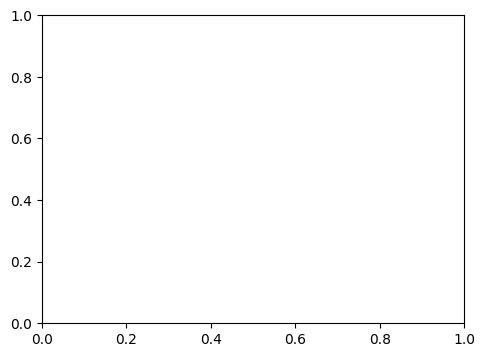

In [ ]:

import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Training and Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, val_f1_scores, label="Validation Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("ANN Validation Macro F1")
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:

import os

model_dir = "/content/drive/MyDrive/APS360_Wafer_Project/models"
os.makedirs(model_dir, exist_ok=True)

torch.save(
    {
        "model_state_dict": ann_model.state_dict(),
        "class_to_idx": class_to_idx,
        "best_val_f1": best_val_f1,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "val_f1_scores": val_f1_scores
    },
    os.path.join(model_dir, "ann_baseline.pth")
)

print("ANN baseline saved successfully!")


In [ ]:
print("model exists:", "model" in globals())
print("ann_model exists:", "ann_model" in globals())
print("WaferANN exists:", "WaferANN" in globals())

ANN Validation Classification Report:
              precision    recall  f1-score   support

      Center       0.02      1.00      0.05       644
       Donut       0.00      0.00      0.00        83
    Edge-Loc       0.00      0.00      0.00       778
   Edge-Ring       0.00      0.00      0.00      1452
         Loc       0.00      0.00      0.00       539
   Near-full       0.00      0.00      0.00        23
      Random       0.00      0.00      0.00       130
     Scratch       0.00      0.00      0.00       179
        none       0.00      0.00      0.00     22114

    accuracy                           0.02     25942
   macro avg       0.00      0.11      0.01     25942
weighted avg       0.00      0.02      0.00     25942



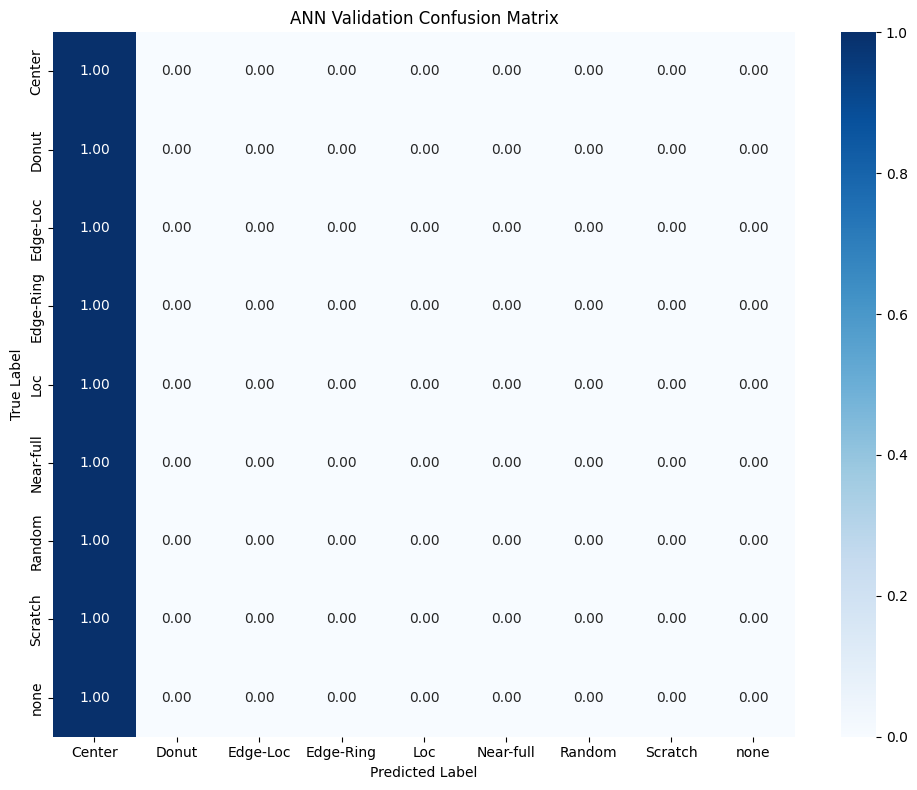

In [ ]:

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
model = ann_model
model.eval()


all_preds = []
all_true = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_true.extend(labels.numpy())

print("ANN Validation Classification Report:")
print(
    classification_report(
        all_true,
        all_preds,
        labels=list(range(len(classes))),
        target_names=classes,
        zero_division=0
    )
)

cm = confusion_matrix(
    all_true,
    all_preds,
    labels=list(range(len(classes))),
    normalize="true"
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("ANN Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

import torch
import torch.nn as nn
from torchvision.models import resnet18

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Build ResNet-18 from scratch
resnet_model = resnet18(weights=None)

# Modify first convolution for single-channel wafer maps
resnet_model.conv1 = nn.Conv2d(
    in_channels=1,
    out_channels=64,
    kernel_size=3,
    stride=1,
    padding=1,
    bias=False
)

# Remove initial max pooling to preserve spatial detail
resnet_model.maxpool = nn.Identity()

# Modify final layer for 9-class classification
resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    len(classes)
)

resnet_model = resnet_model.to(device)

print("Using device:", device)
print("Number of classes:", len(classes))
print("Total parameters:", sum(
    p.numel() for p in resnet_model.parameters()
))

# Test forward pass
dummy_input = torch.randn(2, 1, 64, 64).to(device)

with torch.no_grad():
    output = resnet_model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)


Using device: cuda
Number of classes: 9
Total parameters: 11172297
Input shape: torch.Size([2, 1, 64, 64])
Output shape: torch.Size([2, 9])


In [ ]:

import torch

class AugmentedWaferDataset(WaferDataset):
    def __getitem__(self, idx):
        image, label = super().__getitem__(idx)

        # Random rotation: 0, 90, 180, or 270 degrees
        k = torch.randint(0, 4, (1,)).item()
        image = torch.rot90(image, k, dims=(1, 2))

        # Random horizontal flip
        if torch.rand(1).item() < 0.5:
            image = torch.flip(image, dims=(2,))

        return image, label


train_dataset_aug = AugmentedWaferDataset(
    df_labeled,
    train_idx,
    class_to_idx
)

print("Augmented training samples:", len(train_dataset_aug))

image, label = train_dataset_aug[0]

print("Image shape:", image.shape)
print("Label:", classes[label.item()])


Augmented training samples: 121065
Image shape: torch.Size([1, 64, 64])
Label: none


In [ ]:

from torch.utils.data import DataLoader

batch_size = 64

resnet_train_loader = DataLoader(
    train_dataset_aug,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

resnet_val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(resnet_train_loader))
print("Validation batches:", len(resnet_val_loader))


Training batches: 1892
Validation batches: 406


In [ ]:

import numpy as np
import torch.nn as nn
import torch.optim as optim

train_labels = df_labeled.loc[train_idx, "failure_label"]

class_counts = np.array([
    (train_labels == label).sum()
    for label in classes
], dtype=np.float32)

# Less aggressive weighting
weights = np.sqrt(
    len(train_labels) / (len(classes) * class_counts)
)

# Normalize weights for easier interpretation
weights = weights / weights.mean()

class_weights_resnet = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)

print("ResNet class weights:")
for label, weight in zip(classes, weights):
    print(f"{label}: {weight:.4f}")

resnet_criterion = nn.CrossEntropyLoss(
    weight=class_weights_resnet
)

resnet_optimizer = optim.AdamW(
    resnet_model.parameters(),
    lr=0.0003,
    weight_decay=0.0001
)


ResNet class weights:
Center: 0.5583
Donut: 1.5520
Edge-Loc: 0.5079
Edge-Ring: 0.3719
Loc: 0.6104
Near-full: 3.0015
Random: 1.2434
Scratch: 1.0593
none: 0.0953


In [ ]:

import os
import copy
from sklearn.metrics import accuracy_score, f1_score

num_epochs = 10
best_val_f1 = -1.0

resnet_train_losses = []
resnet_val_losses = []
resnet_val_accuracies = []
resnet_val_f1_scores = []

save_dir = "/content/drive/MyDrive/APS360_Wafer_Project/models"
os.makedirs(save_dir, exist_ok=True)

best_model_path = os.path.join(
    save_dir, "resnet18_best.pth"
)

for epoch in range(num_epochs):

    # Training
    resnet_model.train()
    train_loss_sum = 0.0

    for images, labels in resnet_train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        resnet_optimizer.zero_grad()

        outputs = resnet_model(images)
        loss = resnet_criterion(outputs, labels)

        loss.backward()
        resnet_optimizer.step()

        train_loss_sum += loss.item() * images.size(0)

    train_loss = train_loss_sum / len(train_dataset_aug)
    resnet_train_losses.append(train_loss)

    # Validation
    resnet_model.eval()
    val_loss_sum = 0.0
    all_preds = []
    all_true = []

    with torch.no_grad():
        for images, labels in resnet_val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = resnet_model(images)
            loss = resnet_criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            all_preds.extend(predictions.cpu().numpy())
            all_true.extend(labels.cpu().numpy())

    val_loss = val_loss_sum / len(val_dataset)
    val_accuracy = accuracy_score(all_true, all_preds)
    val_macro_f1 = f1_score(
        all_true,
        all_preds,
        labels=list(range(len(classes))),
        average="macro",
        zero_division=0
    )

    resnet_val_losses.append(val_loss)
    resnet_val_accuracies.append(val_accuracy)
    resnet_val_f1_scores.append(val_macro_f1)

    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": resnet_model.state_dict(),
            "classes": classes,
            "best_val_f1": best_val_f1
        }, best_model_path)

        print("  Best model saved!")

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

print("\nBest Validation Macro F1:", round(best_val_f1, 4))
print("Best checkpoint:", best_model_path)


KeyboardInterrupt: 

In [ ]:

# Actual results from your completed ResNet-18 training

resnet_train_losses = [
    0.3114, 0.2622, 0.2357, 0.2153, 0.2018,
    0.1898, 0.1830, 0.1727, 0.1689, 0.1589
]

resnet_val_losses = [
    0.3902, 0.2410, 0.2768, 0.2160, 0.2295,
    0.2428, 0.2014, 0.1736, 0.1749, 0.1762
]

resnet_val_accuracies = [
    0.9583, 0.9667, 0.9254, 0.9661, 0.9541,
    0.9369, 0.9587, 0.9678, 0.9607, 0.9716
]

resnet_val_f1_scores = [
    0.7718, 0.8354, 0.7633, 0.8224, 0.8030,
    0.7919, 0.8194, 0.8459, 0.8419, 0.8510
]

print("Training history restored!")
print("Best Validation Macro F1:", max(resnet_val_f1_scores))


In [ ]:

import matplotlib.pyplot as plt

epochs = range(1, len(resnet_train_losses) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, resnet_train_losses, marker="o",
         label="Training Loss")
plt.plot(epochs, resnet_val_losses, marker="o",
         label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Weighted Cross-Entropy Loss")
plt.title("ResNet-18 Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs, resnet_val_accuracies, marker="o",
         label="Validation Accuracy")
plt.plot(epochs, resnet_val_f1_scores, marker="o",
         label="Validation Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("ResNet-18 Validation Performance")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
import torch

checkpoint_path = "/content/drive/MyDrive/APS360_Wafer_Project/models/resnet18_best.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))
if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

Checkpoint type: <class 'dict'>
Checkpoint keys: ['epoch', 'model_state_dict', 'classes', 'best_val_f1']


In [ ]:

import torch
import numpy as np
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score
)

# Load best model weights
resnet_model.load_state_dict(checkpoint["model_state_dict"])
resnet_model = resnet_model.to(device)
resnet_model.eval()

print("Best epoch:", checkpoint["epoch"])
print("Saved validation Macro F1:", checkpoint["best_val_f1"])

# Use class order saved in checkpoint
classes = checkpoint["classes"]

all_preds = []
all_true = []

with torch.no_grad():
    for images, labels in resnet_val_loader:
        images = images.to(device)

        outputs = resnet_model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_true.extend(labels.cpu().numpy())

print("\nValidation Accuracy:",
      accuracy_score(all_true, all_preds))

print("Validation Macro F1:",
      f1_score(all_true, all_preds, average="macro"))

print("\nResNet-18 Validation Classification Report:")
print(
    classification_report(
        all_true,
        all_preds,
        labels=list(range(len(classes))),
        target_names=classes,
        digits=4,
        zero_division=0
    )
)


Best epoch: 10
Saved validation Macro F1: 0.8509929058977793

Validation Accuracy: 0.9715519235217023
Validation Macro F1: 0.8509929058977793

ResNet-18 Validation Classification Report:
              precision    recall  f1-score   support

      Center     0.9242    0.9472    0.9356       644
       Donut     0.7476    0.9277    0.8280        83
    Edge-Loc     0.7725    0.8728    0.8196       778
   Edge-Ring     0.9655    0.9828    0.9741      1452
         Loc     0.8277    0.6865    0.7505       539
   Near-full     0.7188    1.0000    0.8364        23
      Random     0.8846    0.8846    0.8846       130
     Scratch     0.5208    0.8380    0.6424       179
        none     0.9922    0.9837    0.9879     22114

    accuracy                         0.9716     25942
   macro avg     0.8171    0.9026    0.8510     25942
weighted avg     0.9742    0.9716    0.9723     25942



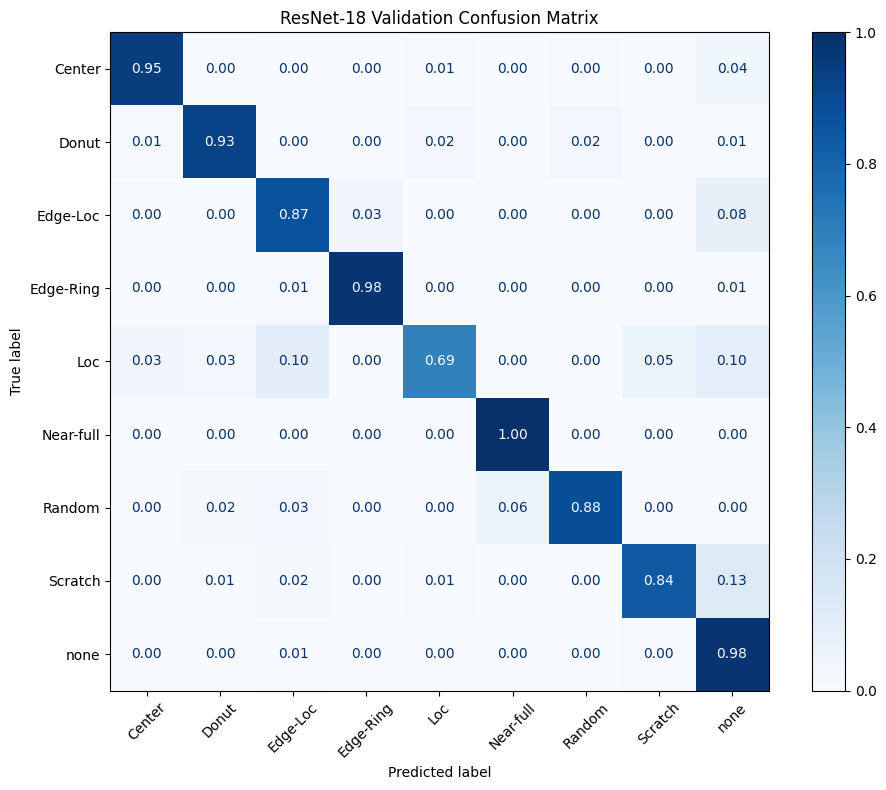

Confusion matrix saved: /content/drive/MyDrive/APS360_Wafer_Project/resnet_confusion_matrix.png


In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    all_true,
    all_preds,
    labels=list(range(len(classes))),
    normalize="true"
)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=45
)

plt.title("ResNet-18 Validation Confusion Matrix")
plt.tight_layout()

save_path = (
    "/content/drive/MyDrive/APS360_Wafer_Project/"
    "resnet_confusion_matrix.png"
)

fig.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix saved:", save_path)


Test Accuracy: 0.970473730871526
Test Macro F1: 0.8554928124696682

ResNet-18 Test Classification Report:
              precision    recall  f1-score   support

      Center     0.8892    0.9472    0.9173       644
       Donut     0.7212    0.9036    0.8021        83
    Edge-Loc     0.7475    0.8703    0.8043       779
   Edge-Ring     0.9707    0.9828    0.9767      1452
         Loc     0.8106    0.6827    0.7412       539
   Near-full     0.8148    1.0000    0.8980        22
      Random     0.8828    0.8692    0.8760       130
     Scratch     0.5616    0.9162    0.6964       179
        none     0.9929    0.9821    0.9875     22115

    accuracy                         0.9705     25943
   macro avg     0.8213    0.9060    0.8555     25943
weighted avg     0.9734    0.9705    0.9713     25943



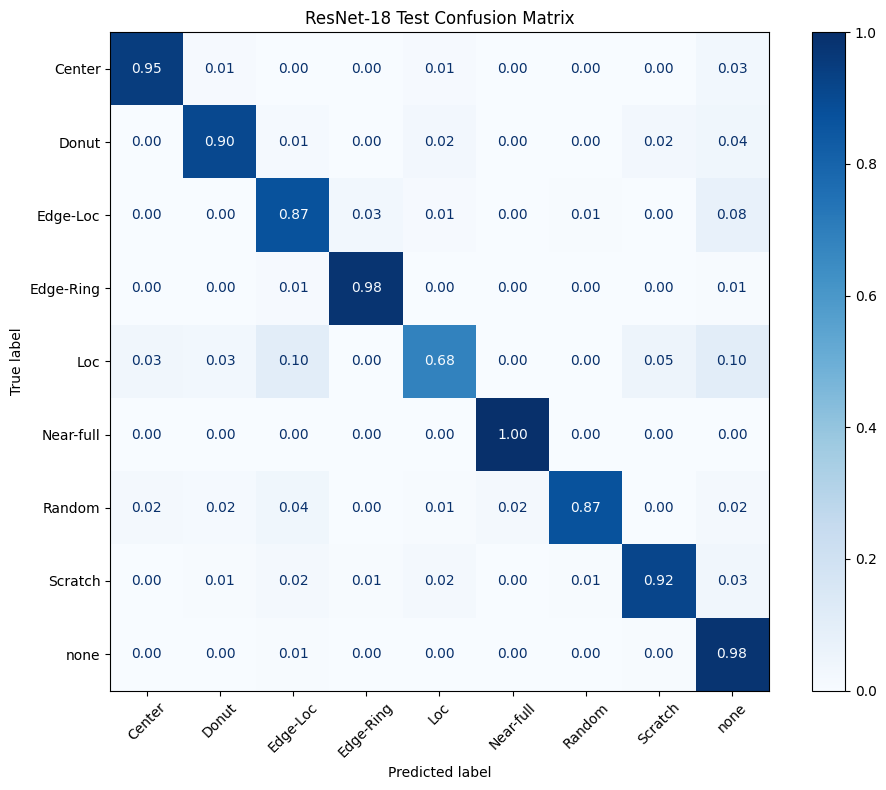

In [ ]:

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import torch

# Create test loader without augmentation
resnet_test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Evaluate saved best model
resnet_model.load_state_dict(checkpoint["model_state_dict"])
resnet_model.to(device)
resnet_model.eval()

test_preds = []
test_true = []

with torch.no_grad():
    for images, labels in resnet_test_loader:
        images = images.to(device)

        outputs = resnet_model(images)
        predictions = outputs.argmax(dim=1)

        test_preds.extend(predictions.cpu().numpy())
        test_true.extend(labels.cpu().numpy())

print("Test Accuracy:",
      accuracy_score(test_true, test_preds))

print("Test Macro F1:",
      f1_score(test_true, test_preds, average="macro"))

print("\nResNet-18 Test Classification Report:")
print(
    classification_report(
        test_true,
        test_preds,
        labels=list(range(len(classes))),
        target_names=classes,
        digits=4,
        zero_division=0
    )
)

# Plot test confusion matrix
cm_test = confusion_matrix(
    test_true,
    test_preds,
    labels=list(range(len(classes))),
    normalize="true"
)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=45
)

plt.title("ResNet-18 Test Confusion Matrix")
plt.tight_layout()

fig.savefig(
    "/content/drive/MyDrive/APS360_Wafer_Project/resnet_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:
print(type(ann_model))

<class '__main__.WaferANN'>


In [ ]:
from sklearn.metrics import accuracy_score, f1_score

ann_model.eval()

ann_val_preds = []
ann_val_true = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = ann_model(images)
        predictions = outputs.argmax(dim=1)

        ann_val_preds.extend(predictions.cpu().numpy())
        ann_val_true.extend(labels.cpu().numpy())

print("Restored ANN Validation Accuracy:",
      accuracy_score(ann_val_true, ann_val_preds))

print("Restored ANN Validation Macro F1:",
      f1_score(ann_val_true, ann_val_preds, average="macro"))

Restored ANN Validation Accuracy: 0.8764937167527561
Restored ANN Validation Macro F1: 0.29935190048762805


In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report
import torch

ann_model.eval()

ann_test_preds = []
ann_test_true = []

with torch.no_grad():
    for images, labels in ann_test_loader:
        images = images.to(device)

        outputs = ann_model(images)
        predictions = outputs.argmax(dim=1)

        ann_test_preds.extend(predictions.cpu().numpy())
        ann_test_true.extend(labels.cpu().numpy())

print("ANN Test Accuracy:",
      accuracy_score(ann_test_true, ann_test_preds))

print("ANN Test Macro F1:",
      f1_score(ann_test_true, ann_test_preds, average="macro"))

print("\nANN Test Classification Report:")
print(
    classification_report(
        ann_test_true,
        ann_test_preds,
        labels=list(range(len(classes))),
        target_names=classes,
        digits=4,
        zero_division=0
    )
)

ANN Test Accuracy: 0.8776548587287515
ANN Test Macro F1: 0.30131373385281895

ANN Test Classification Report:
              precision    recall  f1-score   support

      Center     0.4911    0.7267    0.5861       644
       Donut     0.0000    0.0000    0.0000        83
    Edge-Loc     0.2185    0.5071    0.3054       779
   Edge-Ring     0.9830    0.7961    0.8798      1452
         Loc     0.0000    0.0000    0.0000       539
   Near-full     0.0000    0.0000    0.0000        22
      Random     0.0000    0.0000    0.0000       130
     Scratch     0.0000    0.0000    0.0000       179
        none     0.9429    0.9383    0.9406     22115

    accuracy                         0.8777     25943
   macro avg     0.2928    0.3298    0.3013     25943
weighted avg     0.8776    0.8777    0.8748     25943



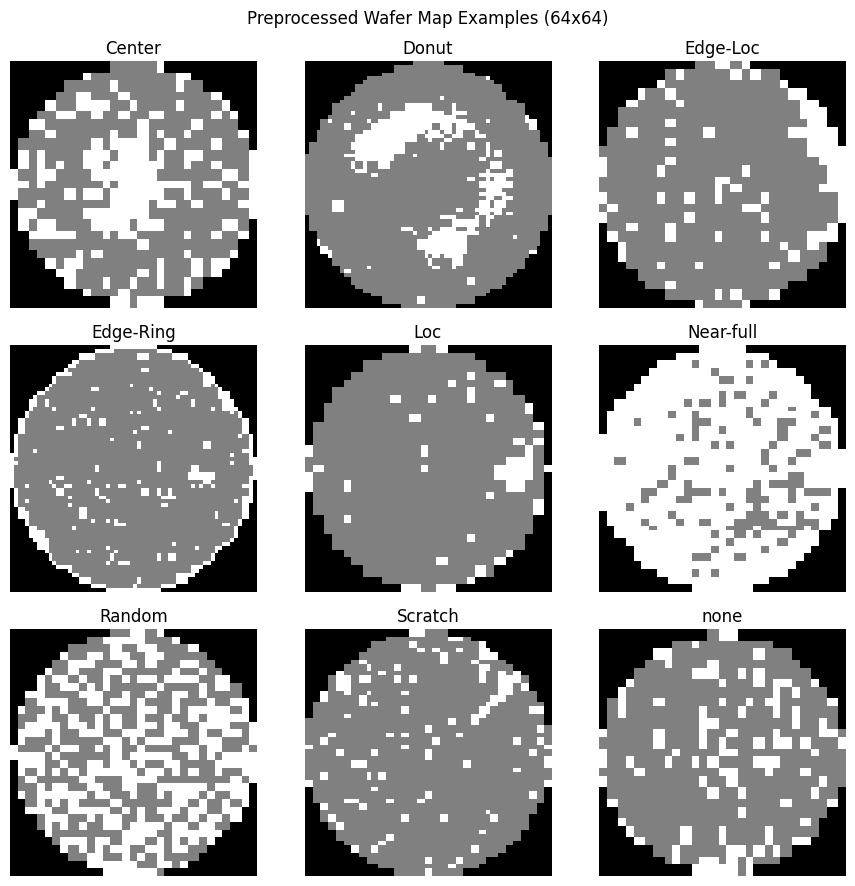

Saved: wafer_map_examples.png


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import os

# One training example from each class
fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for i, class_name in enumerate(classes):
    ax = axes.flat[i]

    # Find an example in the training dataset
    sample_idx = next(
        j for j in range(len(train_dataset))
        if train_dataset.data.iloc[j]["failure_label"] == class_name
    )

    image, label = train_dataset[sample_idx]

    ax.imshow(
        image.squeeze().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    ax.set_title(class_name)
    ax.axis("off")

plt.suptitle("Preprocessed Wafer Map Examples (64x64)")
plt.tight_layout()

save_dir = "/content/drive/MyDrive/APS360_Wafer_Project"
os.makedirs(save_dir, exist_ok=True)

fig.savefig(
    os.path.join(save_dir, "wafer_map_examples.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: wafer_map_examples.png")


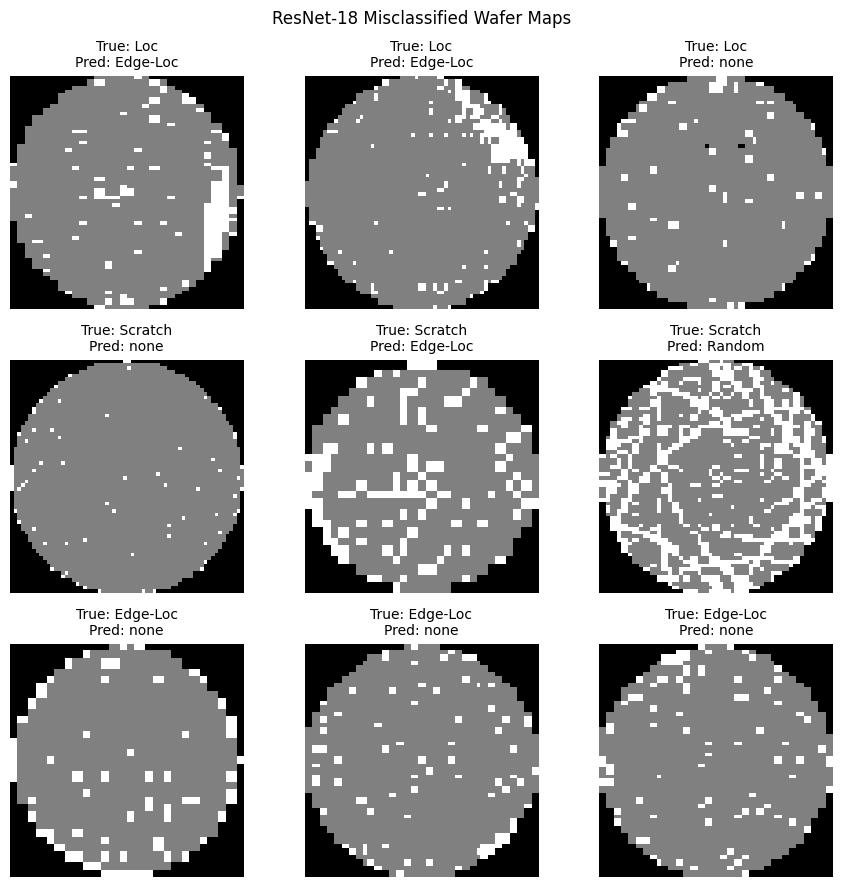

Saved: resnet_misclassified_examples.png


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import os

# Find misclassified test samples
test_true_arr = np.array(test_true)
test_preds_arr = np.array(test_preds)

# Prioritize classes with interesting errors
target_classes = ["Loc", "Scratch", "Edge-Loc"]

selected_indices = []

for class_name in target_classes:
    class_id = classes.index(class_name)

    wrong_indices = np.where(
        (test_true_arr == class_id) &
        (test_preds_arr != class_id)
    )[0]

    selected_indices.extend(wrong_indices[:3].tolist())

# Plot selected misclassified samples
fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for ax, idx in zip(axes.flat, selected_indices):
    image, true_label = test_dataset[idx]

    predicted_label = test_preds_arr[idx]

    ax.imshow(
        image.squeeze().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    ax.set_title(
        f"True: {classes[int(true_label)]}\n"
        f"Pred: {classes[int(predicted_label)]}",
        fontsize=10
    )
    ax.axis("off")

for ax in axes.flat[len(selected_indices):]:
    ax.axis("off")

plt.suptitle("ResNet-18 Misclassified Wafer Maps")
plt.tight_layout()

save_dir = "/content/drive/MyDrive/APS360_Wafer_Project"
os.makedirs(save_dir, exist_ok=True)

fig.savefig(
    os.path.join(save_dir, "resnet_misclassified_examples.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: resnet_misclassified_examples.png")
